In [1]:
import pandas as pd
df = pd.read_csv("data/raw/nlsy97/NLSY97_expanded.csv")
print(df.shape)

(8984, 12)


In [2]:
print(df.columns.tolist())
df.head()

['R0000100', 'R0536300', 'R0536401', 'R0536402', 'R1204500', 'R1235800', 'R1302400', 'R1302500', 'R1482600', 'U5753300', 'U5753500', 'Z9061911']


,R0000100,R0536300,R0536401,R0536402,R1204500,R1235800,R1302400,R1302500,R1482600,U5753300,U5753500,Z9061911
0,1,2,9,1981,-3,1,16,8,4,-5,-5,0
1,2,1,7,1982,-4,1,17,15,2,1,115000,52
2,3,2,9,1983,63000,1,-3,12,2,0,-4,0
3,4,2,2,1981,11700,1,12,12,2,1,45000,52
4,5,1,10,1982,-3,1,12,12,2,1,150000,52


In [3]:
df["U5753500"].describe()

count      8984.000000
mean      36405.141696
std       54970.030437
min          -5.000000
25%          -5.000000
50%       18000.000000
75%       55067.750000
max      380288.000000
Name: U5753500, dtype: float64

In [4]:
(df["U5753500"] < 0).sum()

np.int64(3783)

In [5]:
df["U5753300"].value_counts().sort_index()

U5753300
-5    2271
-3       1
-2       9
-1      46
 0    1162
 1    5495
Name: count, dtype: int64

In [6]:
pd.crosstab(df["U5753300"], df["U5753500"] < 0)

U5753500,False,True
U5753300,,
-5,0,2271
-3,0,1
-2,0,9
-1,1,45
0,0,1162
1,5200,295


In [7]:
import numpy as np

df["has_earnings"] = np.where(df["U5753300"] == 1, 1.0, np.where(df["U5753300"] == 0, 0.0, np.nan))
df["has_earnings"].value_counts(dropna=False)

has_earnings
1.0    5495
NaN    2327
0.0    1162
Name: count, dtype: int64

In [8]:
print(df["R0536300"].value_counts().sort_index())
print(df["R1482600"].value_counts().sort_index())

R0536300
1    4599
2    4385
Name: count, dtype: int64
R1482600
1    2335
2    1901
3      83
4    4665
Name: count, dtype: int64


In [9]:
df["sex"] = df["R0536300"].map({1: "Male", 2: "Female"})
df["race_ethnicity"] = df["R1482600"].map({1: "Black", 2: "Hispanic", 3: "Mixed", 4: "Non-Black, Non-Hispanic"})
print(df["sex"].value_counts())
print(df["race_ethnicity"].value_counts())

sex
Male      4599
Female    4385
Name: count, dtype: int64
race_ethnicity
Non-Black, Non-Hispanic    4665
Black                      2335
Hispanic                   1901
Mixed                        83
Name: count, dtype: int64


In [10]:
missing_codes = [-1, -2, -3, -4, -5]

for col in ["R1204500", "R1302400", "R1302500"]:
    df[col] = df[col].replace(missing_codes, np.nan)

for col in ["R1302400", "R1302500"]:
    df[col] = df[col].replace(95, np.nan)

df["father_education"] = df["R1302400"]
df["mother_education"] = df["R1302500"]

df[["R1204500", "father_education", "mother_education"]].isna().sum()

R1204500            2396
father_education    1864
mother_education     694
dtype: int64

In [11]:
f3 = df[df["has_earnings"].notna() & df["R1204500"].notna()].copy()
f3["parent_income_rank"] = f3["R1204500"].rank(pct=True) * 100

print(len(f3))
f3["parent_income_rank"].describe()

4925


count    4925.000000
mean       50.010152
std        28.870186
min         0.020305
25%        25.370558
50%        50.263959
75%        75.045685
max        99.086294
Name: parent_income_rank, dtype: float64

In [12]:
f3["parent_grade"] = f3[["father_education", "mother_education"]].max(axis=1)

f3["parent_education"] = pd.cut(
    f3["parent_grade"],
    bins=[-1, 11, 12, 15, 25],
    labels=["Less than high school", "High school", "Some college", "College or more"]
)

f3["parent_education"].value_counts(dropna=False)

parent_education
High school              1604
Some college             1224
College or more          1196
Less than high school     723
NaN                       178
Name: count, dtype: int64

In [13]:
import statsmodels.formula.api as smf

model_df = f3.dropna(subset=["parent_education"]).copy()
model_df["parent_education"] = model_df["parent_education"].astype(str)

formula = "has_earnings ~ parent_income_rank + C(parent_education) + C(sex) + C(race_ethnicity)"
res = smf.logit(formula, data=model_df).fit()

ci = res.conf_int()
odds = pd.DataFrame({
    "OR": np.exp(res.params),
    "CI_low": np.exp(ci[0]),
    "CI_high": np.exp(ci[1]),
    "p": res.pvalues
}).round(3)

print(int(res.nobs))
odds

Optimization terminated successfully.
         Current function value: 0.441006
         Iterations 6
4747


,OR,CI_low,CI_high,p
Intercept,3.123,2.331,4.183,0.000
C(parent_education)[T.High school],0.747,0.591,0.945,0.015
C(parent_education)[T.Less than high school],0.462,0.349,0.613,0.000
C(parent_education)[T.Some college],0.832,0.652,1.061,0.139
C(sex)[T.Male],1.464,1.253,1.710,0.000
C(race_ethnicity)[T.Hispanic],1.448,1.153,1.820,0.001
C(race_ethnicity)[T.Mixed],1.167,0.471,2.891,0.738
"C(race_ethnicity)[T.Non-Black, Non-Hispanic]",1.226,1.013,1.484,0.036
parent_income_rank,1.008,1.005,1.011,0.000


In [14]:
model_df["income_group"] = pd.qcut(
    model_df["parent_income_rank"], 4,
    labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"]
)

rows = []
for g in model_df["income_group"].cat.categories:
    scen = model_df.copy()
    scen["parent_income_rank"] = model_df.loc[model_df["income_group"] == g, "parent_income_rank"].mean()
    rows.append({"group": g, "predicted_prob": res.predict(scen).mean()})

pd.DataFrame(rows).round(3)

,group,predicted_prob
0,Q1 (lowest),0.789
1,Q2,0.821
2,Q3,0.848
3,Q4 (highest),0.872


          group   prob    low   high
0   Q1 (lowest)  0.789  0.765  0.807
1            Q2  0.821  0.808  0.831
2            Q3  0.848  0.835  0.859
3  Q4 (highest)  0.872  0.854  0.888


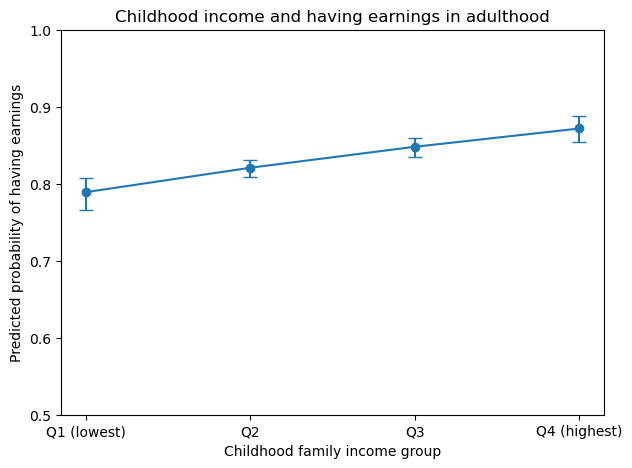

In [15]:
import matplotlib.pyplot as plt
from pathlib import Path

X = res.model.exog.copy()
idx = res.model.exog_names.index("parent_income_rank")
rng = np.random.default_rng(0)
draws = rng.multivariate_normal(res.params.values, res.cov_params().values, size=1000)

rows = []
for g in model_df["income_group"].cat.categories:
    Xg = X.copy()
    Xg[:, idx] = model_df.loc[model_df["income_group"] == g, "parent_income_rank"].mean()
    point = (1 / (1 + np.exp(-Xg @ res.params.values))).mean()
    sims = (1 / (1 + np.exp(-Xg @ draws.T))).mean(axis=0)
    rows.append({"group": g, "prob": point, "low": np.percentile(sims, 2.5), "high": np.percentile(sims, 97.5)})

pp = pd.DataFrame(rows)
print(pp.round(3))

fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(pp["group"], pp["prob"], yerr=[pp["prob"] - pp["low"], pp["high"] - pp["prob"]], fmt="o-", capsize=5)
ax.set_ylim(0.5, 1.0)
ax.set_xlabel("Childhood family income group")
ax.set_ylabel("Predicted probability of having earnings")
ax.set_title("Childhood income and having earnings in adulthood")
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/finding-three.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:
alt_df = model_df.copy()
alt_df["has_earnings_alt"] = np.where(
    alt_df["U5753500"] > 0, 1.0,
    np.where(alt_df["U5753300"] == 0, 0.0, np.nan)
)
alt_df = alt_df.dropna(subset=["has_earnings_alt"])

alt_formula = formula.replace("has_earnings", "has_earnings_alt")
alt_res = smf.logit(alt_formula, data=alt_df).fit(disp=0)

summary = pd.DataFrame({
    "model": ["Main", "Robustness"],
    "n": [int(res.nobs), int(alt_res.nobs)],
    "OR_per_10_pts": [np.exp(10 * res.params["parent_income_rank"]), np.exp(10 * alt_res.params["parent_income_rank"])],
    "CI_low": [np.exp(10 * res.conf_int().loc["parent_income_rank", 0]), np.exp(10 * alt_res.conf_int().loc["parent_income_rank", 0])],
    "CI_high": [np.exp(10 * res.conf_int().loc["parent_income_rank", 1]), np.exp(10 * alt_res.conf_int().loc["parent_income_rank", 1])],
    "p": [res.pvalues["parent_income_rank"], alt_res.pvalues["parent_income_rank"]]
})
summary.round(3)

,model,n,OR_per_10_pts,CI_low,CI_high,p
0,Main,4747,1.085,1.050,1.120,0.0
1,Robustness,4533,1.089,1.054,1.125,0.0


In [17]:
miss = df[df["R1204500"].notna()].copy()
miss["parent_income_rank"] = miss["R1204500"].rank(pct=True) * 100
miss["income_group"] = pd.qcut(miss["parent_income_rank"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
miss.groupby("income_group", observed=True)["has_earnings"].apply(lambda s: s.isna().mean()).round(3)

income_group
Q1 (lowest)     0.241
Q2              0.246
Q3              0.261
Q4 (highest)    0.262
Name: has_earnings, dtype: float64